# HypeCheck — test the crowd, not just a tweet
**Veritas AI International High School Hackathon 2026 · AI + Finance**
**Team:** Nathaniel Wong · Aaden Yick · Alastair Chu — Malvern College Hong Kong

**Who this is for:** someone watching a memecoin who sees a pile of public posts and wonders whether the wording and the crowd mood deserve any trust. **What goes in:** a batch of public posts. **What comes back:** an estimate of the sample's mood, a guess at tomorrow's direction, and how that guess stacks up against some very dumb rules.

**Bottom line:** the posts did not earn that trust in this experiment. We say it out loud instead of dressing a weak model up as trading advice.

**Try a tweet:** run the two setup cells and use **Check a custom tweet**. For the full study and editable **Enter tweets here** list in Section 9, choose **Runtime → Run all**. See the [technical write-up](https://github.com/adeviwon/hypecheck/blob/main/WRITEUP.md) for timing, feature transforms, and split rules.

**Where we go:** look at real posts → set some simple baselines → train a word-based model → poke at its mistakes → try later dates and new coins → try balanced training and character features → explain the predictions and what we found. Every price outcome is a real historical market observation.

*Prototype only, not financial advice. No complete or live X feed, no causal impact and no trading skill is claimed. This archive was picked over before, so it is exploratory and not independent confirmation.*

In [1]:
#@title Automatic environment setup
import sys,subprocess,json,hashlib,urllib.request,contextlib,io
from pathlib import Path
IN_COLAB="google.colab" in sys.modules
if IN_COLAB:
    pins=["numpy==2.5.4","pandas==3.1.1","pyarrow==26.0.1","scikit-learn==1.9.1","requests==2.34.2","ipython==9.18.1","ipywidgets==8.1.9","transformers==5.23.0","safetensors==0.8.0"]
    subprocess.run([sys.executable,"-m","pip","install","-q",*pins],check=True)
print("Environment ready; actual Google Colab runtime:",IN_COLAB)

Environment ready; actual Google Colab runtime: False


In [2]:
#@title Download and verify study files
SETUP_REV='2ce94ac955100ec37968fdfa404e3ae7af8e430b'
BOOTSTRAP={'colab_setup.py': '48e912fec0f69329b2ed93ef5da6cca4890ec191fa6e84367eece7be2a246cb4', 'notebook_support.py': 'e5dd57e29724851b18e5bd2ebfb9b226b4bb5a72be36b4144a51503ab2e01e70'}
SOURCE_REV='e1ee51c0b61d0f955244e1a6a52bff53a167c84d'
SOURCE_FILES={'sample_pipeline.py': 'ce5f257a3be06365f21a8587a6206ebc20f387449ff6489c664fdf9ec3ad1cd6', 'crowd_snapshot.py': 'a32105c5fff454b15619a718a35997da441580866b0054e57e10861115cb134f', 'crowd_app.py': '9b0c527cd800ae3caee7275c0a63fb72c7284d3a3bacc40afdb680e6b40ce081', 'test_sample_pipeline.py': '8a807fdc290380669780665a55dd9b79eb5604bc4dbc67f55f3f5d887af0e7c3', 'test_crowd_snapshot.py': '79cb9c9983d72e729bf069dc6d253125778d9e2e60ba774499c73ccf7caddb4d', 'test_crowd_app.py': '6a050e88d5fb010db242a5f934c6b15c5a674f45ad7485503902bd59785fee02', 'judge_tables.py': '90da7f2881172eb1a0701ad2ee0df7c92221c58d40adf8df6048077ca9d6701f', 'test_judge_tables.py': 'd72143a72278f6d05616380aba5b4af27bb4d9b10d7bbf3881170e0422645058', 'tweet_demo.py': '45cc4ae3dc94018a0041b8acf7503009d6b722cf4ac892a810618f251df4b11e', 'test_tweet_demo.py': '8d459700ef0b04190064b5bffd2a6beaf0a05fb3564445987a1e58c329d88d48'}
def verified_bytes(name,revision,expected):
    url=f"https://raw.githubusercontent.com/adeviwon/hypecheck/{revision}/{name}"
    with urllib.request.urlopen(url,timeout=60) as response:payload=response.read()
    if hashlib.sha256(payload).hexdigest()!=expected:raise ValueError("Changed verified file: "+name)
    return payload
for name,(revision,expected) in {**{n:(SETUP_REV,h) for n,h in BOOTSTRAP.items()},**{n:(SOURCE_REV,h) for n,h in SOURCE_FILES.items()}}.items():
    Path(name).write_bytes(verified_bytes(name,revision,expected))
from colab_setup import prepare
prepare()
import numpy as np,pandas as pd
from IPython.display import display,HTML
from notebook_support import table,accuracy_chart
from sample_pipeline import *
from judge_tables import *
import tweet_demo as td
print("Pinned sources and actual market inputs verified; no downloaded forecasts.")

Verified source and market data. Sentiment: verified cache
Pinned sources and actual market inputs verified; no downloaded forecasts.


## Try your own tweet
Run the two setup cells, choose the coin, paste one tweet and run **Check a custom tweet**. It uses the published model, so it works before the study is trained. Section 9 rates a whole list of posts at once and scores them against what the market did.

In [3]:
#@title Check a custom tweet
tweet_text = "" #@param {type:"string", placeholder:"Paste one tweet as plain text"}
coin = "DOGE" #@param ["DOGE", "SHIB", "PEPE", "BONK", "FLOKI", "WIF", "TRUMP", "NEIRO", "PENGU", "PNUT", "TURBO", "BOME", "MEME"]
published_model_pin = ('artifacts/crowd-model.json', 'bec5fe039f8c82cdba17a6c44db3d5c41e173c32', '511f2ac5477051048f152ea957f5bb25e4004ba17ab606e8fe43a44f9e2b283b')
if tweet_text.strip():
    from crowd_app import panels
    if "published_model" not in globals():
        published_model = json.loads(verified_bytes(*published_model_pin))
    tweet_csv = pd.DataFrame({"text": [tweet_text]}).to_csv(index=False)
    custom_forecast = batch_check(tweet_csv, coin, artifact=published_model, input_format="csv")
    for content in panels(custom_forecast, published_model["report"]):
        display(HTML(content))
else:
    print("Paste a tweet, choose its coin and run this cell.")

Paste a tweet, choose its coin and run this cell.


## 1. Load the data
Real public X posts, real daily Binance prices. Frozen FinTwitBERT estimates the language sentiment; the next-day labels come from the **actual market**, not from the sentiment model. The forecast models downstream get trained during this run. The transformers are **not fine-tuned**.

In [4]:
frame,train,later,unseen=dataset()
print(f"Training: {len(train):,} snapshots; later-time test: {len(later):,}; unseen-coin test: {len(unseen):,}.")

Training: 991 snapshots; later-time test: 155; unseen-coin test: 99.


## 2. Look at the data first
Before fitting anything, we look at real posts and what the market actually did afterwards. Each row is one batch of same-coin posts, seen at a particular UTC cutoff and covering the preceding 24 hours. Several snapshots can share one coin-day outcome, so each coin-day counts with total weight one. Sentiment describes this supplied archive sample, not all of X. **Bullish language** and **bearish language** are average AI language scores shown as percentages — they are not the probability that the coin will move up or down. **Actual next-day result** is measured from market prices, not predicted.

In [5]:
examples=examples_table(train)
table(examples.drop(columns=["Example wording"]),"Post batches, language scores and actual next-day results")
table(examples[["Forecast day (UTC)","Coin","Example wording"]],"Example public wording, kept separate so the data table stays readable")
from IPython.display import Markdown
display(Markdown("**What these examples show:** "+examples_findings(train.head(5))))
print("Established training coins:",BASE_COINS)
print("Excluded from supervised training:",NEW_COINS)

Established training coins: ('DOGE', 'SHIB', 'PEPE', 'BONK', 'FLOKI')
Excluded from supervised training: ('WIF', 'TRUMP', 'NEIRO', 'PENGU', 'PNUT', 'TURBO', 'BOME', 'MEME')


Snapshot time (UTC),Forecast day (UTC),Coin,Posts,Bullish language,Bearish language,Actual next-day result
"22 Mar 2024, 06:29",23 Mar 2024,DOGE,1,99.8%,0.0%,Rose (+5.86%)
"22 Mar 2024, 10:29",23 Mar 2024,DOGE,2,98.7%,1.2%,Rose (+5.86%)
"22 Mar 2024, 07:19",23 Mar 2024,FLOKI,1,86.4%,6.5%,Rose (+0.87%)
"31 Mar 2024, 12:02",01 Apr 2024,DOGE,1,75.9%,22.5%,Fell (-6.80%)
"31 Mar 2024, 15:02",01 Apr 2024,DOGE,2,72.0%,26.5%,Fell (-6.80%)


Forecast day (UTC),Coin,Example wording
23 Mar 2024,DOGE,$doge legit best looking major by a mile atm imo
23 Mar 2024,DOGE,$doge legit best looking major by a mile atm imo Bagged some Being honest here. I think $doge gonna pull numbers over the coming 3/4 week…
23 Mar 2024,FLOKI,The doge of this cycle should go for the next round anytime now IMO. After consolidation comes continuation. Invalidation below the horiz…
01 Apr 2024,DOGE,$DOGE 12H away from highest weekly close in 123 weeks Probably nothing
01 Apr 2024,DOGE,$DOGE 12H away from highest weekly close in 123 weeks Probably nothing $DOGE to 0.45 real quik 🔮 crystal Ball says


**What these examples show:** For the first DOGE snapshot, the language model gave an average bullish score of 99.8% across 1 post(s). The coin rose (+5.86%) on 23 Mar 2024. This bullish score describes the wording: it is NOT the probability that the price will rise. Another DOGE snapshot scored 75.9% bullish, but the coin fell (-6.80%) the next day. Bullish language and a rising market are different outcomes. Rows for the same coin and forecast day can contain overlapping posts; they are not independent trading examples.

## 3. Split into training and test sets
We also run a stratified random 80/20 split with random_state=42, but only as a **diagnostic** on historical training data. We never treat its score as forecasting evidence, because related snapshots and market dates can land on both sides.

The real financial test is different: earlier calendar dates train, the final 20% of the price calendar tests, with a purge in between. One set holds established coins; the other holds coins we kept out of training entirely. Multi-coin posts that mention an excluded asset get dropped from the established training cohort. This data is new to training, but it is **not independent confirmation** — the archive was explored before.

In [6]:
from sklearn.model_selection import train_test_split
random_train,random_test=train_test_split(train,test_size=.2,stratify=train.actual_up,random_state=42)
table(pd.DataFrame([{ "Purpose":name,"Post batches":len(d),"Distinct coin-days":len(d[["date","coin"]].drop_duplicates()),"Dates with data":d.date.nunique(),"First forecast day":d.date.min().strftime("%d %b %Y"),"Last forecast day":d.date.max().strftime("%d %b %Y")} for name,d in [("Training",train),("Later dates",later),("Unseen coins",unseen)]]))
assert train.date.max()+pd.Timedelta(days=1)<min(later.date.min(),unseen.date.min())
print("Random diagnostic shared dates:",len(set(random_train.date)&set(random_test.date)))

Random diagnostic shared dates: 112


Purpose,Post batches,Distinct coin-days,Dates with data,First forecast day,Last forecast day
Training,991,556,334,23 Mar 2024,02 Dec 2025
Later dates,155,127,91,21 Apr 2026,20 Oct 2026
Unseen coins,99,77,57,23 Apr 2026,03 Oct 2026


## 4. Baselines: simple rules before AI
We pit the AI models against always-up, training majority/prevalence, coin-only, and copying the previous **completed** UTC-day direction at the snapshot cutoff. No half-finished day sneaks in.

We report accuracy, precision and recall for UP, confusion matrices, and **Brier error** (how far off the probabilities are; lower is better). **Correct directions** is how often the forecast matched the market. **UP calls that were right** is precision; **rising days caught** is recall. Those two answer different questions. Every method sees the same rows and the same coin-day weights. High accuracy on its own proves nothing about forecasting value.

In [7]:
from sklearn.linear_model import LogisticRegression
coin_encoder=encoder(coin_only=True)
coin_model=LogisticRegression(max_iter=1000).fit(coin_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
base_models={"Coin only":(coin_encoder,coin_model)}
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    scores,_=evaluate(base_models,train,part)
    table(scores_table(scores),label)
    display(Markdown("**Baseline finding:** "+label+" — the coin-only rule was correct "+format(scores["Coin only"]["accuracy"],".2%")+" of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities."))

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


**Baseline finding:** Later dates — the coin-only rule was correct 51.18% of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities.

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**Baseline finding:** Unseen coins — the coin-only rule was correct 55.84% of the time. The post-based model needs to improve on this, not just produce convincing-looking probabilities.

## 5. Model 1: TF-IDF + logistic regression
We turn word usage into numerical features with TF-IDF, then fit logistic regression to actual price direction. Our fixed extra features represent estimated batch sentiment and coin identity; they remain unchanged between Model 1 and balanced Model 2. TF-IDF, scaling, and the coin vocabulary fit on training data. Unseen coins have an all-zero identity vector. The six scaled inputs are mean bullish-minus-bearish, its standard deviation, mean bullish, bearish and neutral scores, and log(1 + post count). The label is whether the next complete UTC day closes above its open.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
vec=TfidfVectorizer()
word_encoder=ColumnTransformer([("text",vec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
X_train=word_encoder.fit_transform(train)
model1=LogisticRegression(max_iter=1000)
model1.fit(X_train,train.actual_up,sample_weight=weight(train))
models={"Model 1":(word_encoder,model1),**base_models}
score1,pred1=evaluate(models,train,later)
table(scores_table(score1),"Model 1 on later dates")
table(confusion_table(score1["Model 1"]),"Where Model 1 was right or wrong; weighted coin-day equivalents, not raw post counts")
display(Markdown("**What this result means:** "+model_findings(score1)))

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,36.09%,37.35%,39.58%,0.2766,127
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


What actually happened,Model predicted no rise,Model predicted a rise
Did not rise,20.5,42.5
Rose,38.7,25.3


**What this result means:** Model 1 — word-based predicted 36.09% of directions correctly, compared with 51.18% for the coin-only baseline. Of its UP calls, 37.35% were correct; it caught 39.58% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

## 6. Where Model 1 goes wrong
Here are five real held-out mistakes. **Missed a rise** means the model said no rise and the price rose anyway. **Predicted a rise that did not happen** means it cried UP and nothing happened. Those are different mistakes, and neither has a fixed financial cost — losses depend on returns, fees and execution. These are the errors as they happened, not a highlight reel of fake wins.

In [9]:
def inspect_errors(part,prep,model,title):
    p=model.predict_proba(prep.transform(part))[:,1]
    bad=part[((p>=.5)!=part.actual_up)].copy()
    bad["estimated_up"]=p[((p>=.5)!=part.actual_up)]
    bad["error_type"]=np.where(bad.actual_up.eq(1),"Missed UP","False UP")
    bad["estimated_language"]=np.where(bad.bullish>bad.bearish,"More bullish","More bearish/neutral")
    saved=export(prep,model)
    def reasons(row):
        explanation=infer(saved,row.to_dict())
        key="toward_up" if row.estimated_up>=.5 else "toward_down"
        return ", ".join(x["word"] for x in explanation[key][:3])
    shown=bad.head(5).copy();shown["actual_word_reasons"]=shown.apply(reasons,axis=1)
    table(errors_table(shown),title)
    table(bad.groupby(["error_type","estimated_language"]).size().reset_index(name="raw_snapshot_errors").rename(columns={"error_type":"Mistake","estimated_language":"Post language","raw_snapshot_errors":"Wrong batch calls (raw count)"}),"Observed failure patterns; snapshots are dependent")
    print(title+":",len(bad),"wrong of",len(part),"raw snapshots")
inspect_errors(later,word_encoder,model1,"Model 1: later-time errors")

Model 1: later-time errors: 102 wrong of 155 raw snapshots


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,DOGE,Missed a rise,35.2%,Rose (+1.57%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,40.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,42.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,41.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,SHIB,Missed a rise,28.2%,Rose (+0.98%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,1
False UP,More bullish,51
Missed UP,More bearish/neutral,15
Missed UP,More bullish,35


## 7. Our addition: later time and another coin market
Does the model carry over to **later dates**, and to a separate **cohort of coins we kept out of training**? We keep every eligible batch — no invented cases, no picking a class quota. Real subsequent prices decide the outcomes.

We also read off the top 12 learned word coefficients in each direction. They describe this fitted model. They are not economic laws, and they are not evidence that a word moved a price.

In [10]:
market_scores,_=evaluate(models,train,unseen)
table(scores_table(market_scores),"Model 1 on coins excluded from training")
display(Markdown("**What happened on new coins:** "+model_findings(market_scores)))
words=np.array(word_encoder.named_transformers_["text"].get_feature_names_out())
coef=model1.coef_[0][word_encoder.output_indices_["text"]]
table(pd.DataFrame({"Words pushing the model toward a rise":words[np.argsort(coef)[-12:][::-1]],"Words pushing the model toward no rise":words[np.argsort(coef)[:12]]}),"Model 1: top word coefficients")

Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,49.03%,41.98%,40.44%,0.2650,77
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**What happened on new coins:** Model 1 — word-based predicted 49.03% of directions correctly, compared with 55.84% for the coin-only baseline. Of its UP calls, 41.98% were correct; it caught 40.44% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

Words pushing the model toward a rise,Words pushing the model toward no rise
trend,from
weekly,longed
floki,move
bottom,looking
eth,today
below,early
im,down
strongest,memes
good,follow
next,fresh


## 8. Improvement experiment: balanced class weights
We change **one thing only**: class_weight=balanced. Same vocabulary, same numeric features, same training rows, same target. This tests how the model behaves on imbalanced classes — it is not an assumption that catching more UP days makes for better trading decisions. We report both tests again, whether they got better or worse.

In [11]:
model2=LogisticRegression(max_iter=1000,class_weight="balanced")
model2.fit(X_train,train.actual_up,sample_weight=weight(train))
models["Model 2"]=(word_encoder,model2)
for label,part in [("Later dates",later),("Unseen coins",unseen)]:
    result,_=evaluate(models,train,part)
    table(pd.DataFrame([{ "method":name,**{k:v for k,v in row.items() if not k.startswith("confusion")}} for name,row in result.items() if name in ["Model 1","Model 2"]]),label+": before and after the one change")
    inspect_errors(part,word_encoder,model2,"Model 2: "+label+" errors")
    display(Markdown("**What Model 2 achieved:** "+model_findings(result,"Model 2")))

Model 2: Later dates errors: 101 wrong of 155 raw snapshots
Model 2: Unseen coins errors: 57 wrong of 99 raw snapshots


method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.360892,0.373464,0.395833,0.276650,155,127,91
Model 2,0.367454,0.389140,0.447917,0.276796,155,127,91


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,DOGE,Missed a rise,36.2%,Rose (+1.57%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,41.0%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,43.1%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,PEPE,Missed a rise,42.1%,Rose (+0.53%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell
23 Apr 2026,SHIB,Missed a rise,29.1%,Rose (+0.98%),"team, people, biggest",The Solana trenches desperately needed an organic runner like $MAGA People are tired of rugs and the same cabal winning. Fuck the people who buy a coin and sell


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,1
False UP,More bullish,54
Missed UP,More bearish/neutral,14
Missed UP,More bullish,32


**What Model 2 achieved:** Model 2 — balanced word-based predicted 36.75% of directions correctly, compared with 51.18% for the coin-only baseline. Of its UP calls, 38.91% were correct; it caught 44.79% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

method,accuracy,up_precision,up_recall,brier,snapshots,coin_days,dates
Model 1,0.490260,0.419847,0.404412,0.264985,99,77,57
Model 2,0.438312,0.386503,0.463235,0.266244,99,77,57


Forecast day,Coin,Mistake,Estimated chance of UP,Actual result,Words influencing this call,Input wording
23 Apr 2026,NEIRO,Predicted a rise that did not happen,52.4%,Fell (-0.18%),"soon, god",$Neiro & $BERT god candles soon
25 Apr 2026,PENGU,Missed a rise,40.9%,Rose (+2.80%),"today, 25, yesterday",Coffee and charts with @get_truenorth day 2. Hit a winner yesterday on $PENGU and today I'm shifting some focus to $ZEC. Prompting to refine a set up and be mor
25 Apr 2026,TRUMP,Predicted a rise that did not happen,58.0%,Fell (-10.69%),"trump, april",WHITE HOUSE CONFIRMS TRUMP WILL ADDRESS $TRUMP MEMECOIN HOLDERS AT MAR-A-LAGO GALA ON APRIL 25
26 Apr 2026,TRUMP,Missed a rise,40.7%,Rose (+1.56%),,We are winning so much mister president $TRUMP Lmao what a crime show
28 Apr 2026,PENGU,Predicted a rise that did not happen,58.1%,Fell (-1.40%),"time, think, market",What do you think happens to $PENGU when the NFT market rips to new all time highs? Flightless birds will once again fly. $BERT and $PENGU identical patterns an


Mistake,Post language,Wrong batch calls (raw count)
False UP,More bearish/neutral,5
False UP,More bullish,28
Missed UP,More bearish/neutral,9
Missed UP,More bullish,15


**What Model 2 achieved:** Model 2 — balanced word-based predicted 43.83% of directions correctly, compared with 55.84% for the coin-only baseline. Of its UP calls, 38.65% were correct; it caught 46.32% of actual rising days. These are coin-day-weighted rates, not counts of independent trades. It did not beat the no-text baseline.

### One alternative we tried: character n-grams
Instead of whole words we try short character patterns: char_wb, ngrams (2,5), sublinear TF, balanced logistic regression and C=10. Same sentiment and coin features. All results shown. The word-balanced model is declared the readable demo up front, **not chosen because it wins on test accuracy**. Eyeballing these reused tests cannot establish an independent improvement.

In [12]:
cvec=TfidfVectorizer(analyzer="char_wb",ngram_range=(2,5),sublinear_tf=True)
char_encoder=ColumnTransformer([("text",cvec,"text"),("numeric",StandardScaler(),SOCIAL),("coin",OneHotEncoder(handle_unknown="ignore"),["coin"])])
cmodel=LogisticRegression(max_iter=1000,class_weight="balanced",C=10)
cmodel.fit(char_encoder.fit_transform(train),train.actual_up,sample_weight=weight(train))
models["Character trial"]=(char_encoder,cmodel)
def use_visible_models(data):
    return models if data.index.equals(train.index) else fit_models(data)
with contextlib.redirect_stdout(io.StringIO()):
    artifact,report=run_experiment(trainer=use_visible_models)
for name in ["later_time","unseen_coin_market"]:
    table(scores_table(report["tests"][name]),TEST_NAMES[name])
display(Markdown("**What balancing changed:** "+balance_findings(report)))
print("Random 80/20 is diagnostic only:",report["random_80_20_diagnostic"]["status"])
table(pd.DataFrame([{ "Model":MODEL_NAMES.get(m,m),"Random-split accuracy (not a forecasting result)":format(v["accuracy"],".2%")} for m,v in report["random_80_20_diagnostic"]["metrics"].items()]),"Do not confuse this with future forecasting")

Random 80/20 is diagnostic only: Exact sample split reproduced on historical training subset only; NOT a valid forecasting headline because shared dates/outcomes can leak.


Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,36.09%,37.35%,39.58%,0.2766,127
Coin-only baseline,51.18%,52.00%,40.62%,0.2532,127
Model 2 — balanced word-based,36.75%,38.91%,44.79%,0.2768,127
Character-pattern alternative,40.03%,40.76%,41.93%,0.3418,127
Always predict a rise,50.39%,50.39%,100.00%,0.4961,127
Always predict the training majority,49.61%,No UP calls,0.00%,0.5039,127
Training-frequency probability,49.61%,No UP calls,0.00%,0.2503,127
Copy the last completed day,47.24%,47.69%,48.44%,0.5276,127


Model / rule,Correct directions,UP calls that were right,Rising days caught,Probability error ↓,Distinct coin-days
Model 1 — word-based,49.03%,41.98%,40.44%,0.2650,77
Coin-only baseline,55.84%,No UP calls,0.00%,0.2484,77
Model 2 — balanced word-based,43.83%,38.65%,46.32%,0.2662,77
Character-pattern alternative,45.13%,39.88%,47.79%,0.2970,77
Always predict a rise,44.16%,44.16%,100.00%,0.5584,77
Always predict the training majority,55.84%,No UP calls,0.00%,0.4416,77
Training-frequency probability,55.84%,No UP calls,0.00%,0.2487,77
Copy the last completed day,55.84%,50.00%,61.76%,0.4416,77


**What balancing changed:** Later dates: established coins: balanced training changed accuracy from 36.09% to 36.75% (+0.66 percentage points), and rising-day recall by +5.21 points. New coins: excluded from training: balanced training changed accuracy from 49.03% to 43.83% (-5.19 percentage points), and rising-day recall by +5.88 points. Catching more rising days can come with more false UP calls. Balanced weights did not create a dependable forecasting advantage.

Model,Random-split accuracy (not a forecasting result)
Model 1 — word-based,66.46%
Model 2 — balanced word-based,66.77%
Character-pattern alternative,73.91%
Coin-only baseline,52.80%
Always predict a rise,47.83%
Always predict the training majority,52.17%
Training-frequency probability,52.17%
Copy the last completed day,44.10%


### What the character alternative tells us
Later dates: established coins: character features got the direction right 40.03% of the time, against 36.75% for the balanced word model. Probability error was 0.3418 versus 0.2768 (lower is better). New coins: excluded from training: character features got the direction right 45.13% of the time, against 43.83% for the balanced word model. Probability error was 0.2970 versus 0.2662 (lower is better). A fancier text representation did not crack the forecasting problem, and it did not establish trading value.

## 9. The demo: explain a batch forecast
For each word we multiply its TF-IDF value by its learned coefficient, which shows how much that word pushed this particular model. Sentiment and coin contributions get kept separate. The first demonstration uses the **first eligible held-out historical snapshot**, carried in as quoted CSV so blank lines inside original posts survive. It is an illustration, not an independent test.

The three panels separate three different things: estimated language sentiment, the price-direction model's estimate, and whether the evidence actually supports trusting it. No causal price-impact estimate, no guaranteed return.

In [13]:
from crowd_app import panels,build_app
example=later.iloc[0]
result=batch_check(historical_csv(example),example.coin,example.cutoff.isoformat(),artifact=artifact,input_format="csv")
for content in panels(result,report):display(HTML(content))
print("Historical reveal — actual next-day direction:","UP" if example.actual_up else "DOWN / FLAT")
table(pd.DataFrame(result["toward_up"]+result["toward_down"]).rename(columns={"word":"Word","logit_contribution":"Contribution to this model score"}),"Actual word × TF-IDF contributions (logit units)")

Historical reveal — actual next-day direction: UP


Word,Contribution to this model score
forward,0.036360
double,0.031709
created,0.028865
especially,0.026646
holding,0.024437
pepe,-0.053815
moving,-0.051019
narrative,-0.041521
middle,-0.026624
bags,-0.025760


### Enter tweets here
The list below holds **40 real public posts that were held out of training** — 20 from later dates, and 20 about coins the model had never seen. The model rates every one of them, and since their next-day outcomes are already known, the table can show what it got right.

**Swap in your own posts and the same block rates them.** Your own posts get rated but not scored: their outcome hasn't happened yet, so there is nothing honest to mark them against.

Each entry is one post as a quoted string. A post can start with `TICKER | ` to set its coin; otherwise a cashtag in the text, or the `COIN` setting, is used. You can also delete the list and assign one triple-quoted block instead, with a blank line between posts.

In [14]:
#@title Enter tweets here
TWEETS = [
    "BONK | $bonk - after a 40% drop on the playbook that guy made to take a huge chunk of the supply, he's sold and the structure looks bullish short term",
    'BONK | $BONK weirdly strong today, something brewing?',
    'DOGE | $doge will pump just to lead everyone into a false sense of security on alts before they roll back over -30%',
    'DOGE | for memes..my top two plays with conviction are $DOGE and $BERT',
    'DOGE | Added to $DOGE $HYPE $BERT $SOL spot bags',
    'DOGE | KALSHI FILES FOR $XRP, $SOL, $DOGE, $XLM, $LINK, $BCH, $LTC, $SUI, $SHIB, $DOT, $HBAR, AND $ETH PERPETUAL FUTURES AFTER CFTC APPROVES $BTC PERPS',
    'FLOKI | $FLOKI I’m starting to like it for a expansion up',
    'FLOKI | $FLOKI I’ve shown you the entry point right at the absolute low. It remains one of my favourite charts for trading: if BTC forms another temporary low on the lower timeframes, I expect a further upward move.',
    "PEPE | You know it's bad when $BTC is up more from the HTF lows than $PEPE , absolutely no risk appetite and a true pain in the ass to intraday trade",
    'PEPE | No interest in voting but I will long $pepe to make britain great again',
    'PEPE | Closed long scalps and flipped short on $PEPE',
    'PEPE | $pepe - eyes on the daily close',
    'SHIB | $shib - lowkey has my attention in the coming weeks to add some spot',
    'SHIB | $SHIB might be cooking up something',
    'SHIB | $SHIB working on a tweezer top here on daily',
    'BONK | $BONK \n\nDaily looks good for me ,above box remain good',
    'BONK | $BONK h12 \n\nIf we consolidate near the support level, we’ll have a good chance of regaining the previous high',
    'FLOKI | 🐋 WHALE WATCH:Is the cryptocurrency gaming sector over ?\n\nGambling cryptocurrencies have suffered the biggest losses in the entire market.\n\n=> $SAND: -34.94%\n=> $STX: -34.48%\n=> $FLOKI: -30.80%\n=> $AXS: -30.79%\n=> $MANA: -31.61%\n=> $VIRTUAL: -28.52%\n=> $GALA: -28.85%\n=> $IMX: -24.60%\n=> $RENDER: -15.88%\n=> $APE: -16.39%\n=> $WEMIX: -10.65%\n\nAll the major gaming tokens are in the red. Some have lost a third of their value in 30 days.\n\nWhile everyone is declaring the sector dead who is accumulating the losses ?',
    'FLOKI | Corner trader @eliz883 caught the $FLOKI breakout and shared the setup with @WealthGroup before the move.\n\nAfter holding through consolidation, he secured TP1 and is currently sitting at +1.23R with the remainder still running.\n\nAnother well-executed trade from our veteran trader',
    'SHIB | 🐋 WHALE WATCH: The SEC just approved a massive multi asset crypto ETF from T Rowe Price.\n\nThis is a huge shift for institutional money entering the space.\n\nThey are no longer just holding $BTC and $ETH for their clients.\n\nThe fund will include a basket of alts like $SOL $XRP $DOGE and $SHIB.',
    'NEIRO | $Neiro & $BERT god candles soon',
    'PENGU | What’s $PENGU & @LucaNetz cooking up',
    'PENGU | $PENGU Above the support level, I’ll be buying on dumps',
    'PENGU | $PENGU has the cleanest looking chart in crypto 🐧',
    'TRUMP | WHITE HOUSE CONFIRMS TRUMP WILL ADDRESS $TRUMP MEMECOIN HOLDERS AT MAR-A-LAGO GALA ON APRIL 25',
    'TRUMP | selling $trump anytime my indi told me too was the easiest way it seems',
    'TRUMP | When we getting another $TRUMP dinner announcement cauz charts looks rekt mr president',
    'TURBO | $TURBO imo another meme very interesting',
    'WIF | $WIF - Yeah, you know what. If the market is starting to bottom out over a long period then I am fine holding a bag of this.',
    'WIF | Might have another $WIF and $PENGU type setup after this weekly close',
    'BOME | +2.86R on $BOME.\n\n@EricTrader10728 caught the long from 0.0006397 with just 1% risk after spotting the order block flip and volume coming in.\n\nAnother setup shared, executed, and won together inside @WealthGroup.',
    'BOME | 🐋 WHALE WATCH : MEMECOINS ARE MOVING \n\nHype is so real\n\n$CASHCAT +36.10%\n$TIBBIR +23.90%\n$BOME +19.30%\n$BASEDHYPE +15.80%\n$PEOPLE +13.60%\n$SHORT +12.80%\n$AIX +9.10%\n$PUMP +8.30%\n$DOG +7.60%\n$BABYDOGE +5.20%\n\nmeme casino is waking up\n\nWHO’S NEXT TO SEND ?',
    'BOME | +236.4% on $BOME.\n\n@WealthGroup trader @mucitradez shared the long, entering at $0.001255 with just 1% portfolio risk before riding the move to $0.0014528.\n\nExperienced traders finding the opportunities. The community is positioned to capitalize alongside them.',
    'MEME | $MEME filled the gap\n\nIf this chart was an individual stock would you buy it, if TRADr?\n\nSomething to think about before people potentially become long term "community members" in the names this is full of....',
    'MEME | $MEME is such an amazing example of what can happen onchain.\n\nA 15m candle moving a coin from $50m to $150m.\n\nMarkets in momentum, with a narrative, in an environment like this and magic can happen.\n\nSometimes you just have to press the buy button.',
    'NEIRO | Memes started with a dog coin and everyone will round trip back to dog  coins\n\n$DOGE $SHIB $BERT $Neiro',
    'NEIRO | time for dog memes\n\n$DOGE $Neiro $Bert $SHIB',
    'WIF | Whole market is down bad specialy the popular memes from last cycle. $NPC held up pretty well.\n\n$NPC -91%\n$MOG -97%\n$GIGA -97%\n$PONKE -96%\n$APU -98%\n$Wif -96%\n$Popcat -95\n#SPX900 -87',
    'PENGU | Just a matter of time before BoJ adds $Bert  $Pengu and $Doge to their balance sheets',
    'PENGU | feel like $pengu is actually the coin of the week',
]
COIN = "DOGE" #@param ["DOGE", "SHIB", "PEPE", "BONK", "FLOKI", "WIF", "TRUMP", "NEIRO", "PENGU", "PNUT", "TURBO", "BOME", "MEME"]
RATE = True #@param {type:"boolean"}

In [15]:
if RATE:
    tweet_table,tweet_summary,rated=td.run_block(TWEETS,COIN,artifact,known=td.examples())
    table(tweet_table,"Every post, what the model estimated, and what the market actually did")
    display(Markdown("**How many it got right:** "+td.finding(tweet_summary)))
    print("Posts rated:",tweet_summary["rated"],"| with a known outcome:",tweet_summary["scored"])
else:
    print("Set RATE=True to rate the posts in TWEETS.")

Posts rated: 40 | with a known outcome: 40


#,Coin,Public post (shortened),Language reads,Model P(UP),Model says,Market actually did,Model right?,Coin-only says,Coin-only right?
1,BONK,$bonk - after a 40% drop on the playbook that guy made to take a huge chunk of…,more bullish,46.2%,DOWN / FLAT,did not rise,✓,UP,✗
2,BONK,"$BONK weirdly strong today, something brewing?",more bullish,53.3%,UP,did not rise,✗,UP,✗
3,DOGE,$doge will pump just to lead everyone into a false sense of security on alts b…,more bearish/neutral,35.0%,DOWN / FLAT,rose,✗,DOWN / FLAT,✗
4,DOGE,for memes..my top two plays with conviction are $DOGE and $BERT,more bullish,56.2%,UP,did not rise,✗,DOWN / FLAT,✓
5,DOGE,Added to $DOGE $HYPE $BERT $SOL spot bags,more bullish,49.8%,DOWN / FLAT,did not rise,✓,DOWN / FLAT,✓
6,DOGE,"KALSHI FILES FOR $XRP, $SOL, $DOGE, $XLM, $LINK, $BCH, $LTC, $SUI, $SHIB, $DOT…",more bullish,54.3%,UP,did not rise,✗,DOWN / FLAT,✓
7,FLOKI,$FLOKI I’m starting to like it for a expansion up,more bullish,59.2%,UP,rose,✓,DOWN / FLAT,✗
8,FLOKI,$FLOKI I’ve shown you the entry point right at the absolute low. It remains on…,more bullish,52.2%,UP,did not rise,✗,DOWN / FLAT,✓
9,PEPE,"You know it's bad when $BTC is up more from the HTF lows than $PEPE , absolute…",more bearish/neutral,26.4%,DOWN / FLAT,rose,✗,UP,✓
10,PEPE,No interest in voting but I will long $pepe to make britain great again,more bullish,56.4%,UP,did not rise,✗,UP,✗


**How many it got right:** The model got **14 of 40** right (**35.0%**). Saying "up" every time would have got 16 of 40 (40.0%), and the coin-only baseline got 22 of 40 (55.0%). With only 40 posts the uncertainty is wide (about 22% to 50%), so read this as the method being demonstrated rather than a precise score. It points the same way as the larger tests: the wording model does not beat the simple baselines, and these are real posts whose outcomes we did not choose.

## 10. Results summary
Same rows, before and after balanced weights, plus the character alternative. UP precision and recall expose the tradeoff that accuracy hides. Full confusion matrices and test support live in the report. The chart uses the full 0–100% axis.

Paired date-block accuracy differences vs coin-only: {'later_time': {'mean': -0.1443569553805774, 'interval95': [-0.23759155912103244, -0.03939410016977936], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}, 'unseen_coin_market': {'mean': -0.12012987012987013, 'interval95': [-0.24142359470949457, 0.014947808426223293], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}}


Model / rule,Later dates — correct,New coins — correct
Model 1 — word-based,36.09%,49.03%
Coin-only baseline,51.18%,55.84%
Model 2 — balanced word-based,36.75%,43.83%
Character-pattern alternative,40.03%,45.13%
Always predict a rise,50.39%,44.16%
Always predict the training majority,49.61%,55.84%
Training-frequency probability,49.61%,55.84%
Copy the last completed day,47.24%,55.84%


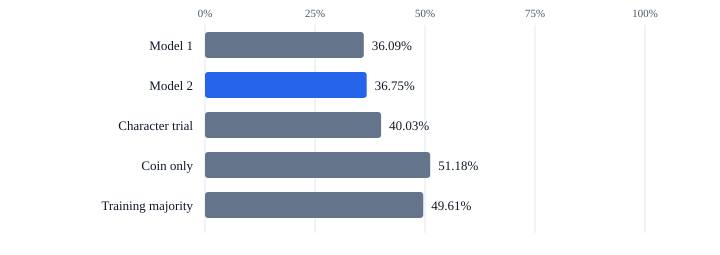

In [16]:
table(results_table(report),"Complete measured comparison")
accuracy_chart({"primary_model":"Model 2","metrics":report["tests"]["later_time"]},["Model 1","Model 2","Character trial","Coin only","Training majority"])
print("Paired date-block accuracy differences vs coin-only:",report["paired_accuracy_vs_coin_only"])

### Our findings, in plain English
Later dates: established coins: the balanced model was correct 36.75% of the time versus 51.18% without post wording or sentiment. New coins: excluded from training: the balanced model was correct 43.83% of the time versus 55.84% without post wording or sentiment. Neither result justifies following the crowd or trading on the model alone. The tested posts did not add useful direction information in this experiment; that does not prove all social information is useless. We have not measured profits or established that posts cause price movements.

## 11. Limitations and next steps
- This is a sparse archive, not every public post about a coin. Estimated sample sentiment is not validated full-population sentiment.
- The later-time and unseen-coin experiments use real prices but reused dates, so they are exploratory, **not independent confirmation**. Small per-coin samples limit what we can conclude.
- Balanced weights may catch more UP days while producing more false alarms or worse accuracy. They do not create trading skill. The character trial can overfit and hands you less readable fragments.
- The probabilities are not independently calibrated. We established no profitability, no fees/slippage, no causal effect and no useful return-magnitude forecast. And do not flip a losing model after peeking at test labels and call that a new validated strategy.
- Next: gather a genuinely new timestamped public sample, freeze this protocol and evaluate it prospectively; also test whether users actually understand the evidence warnings.

**Investor boundary:** this prototype does not justify trading just because a batch sounds bullish or the model says UP. Its useful result is showing how convincing-looking text confidence can fall apart on a fair future-market test.

In [17]:
for filename in ["test_crowd_snapshot.py","test_sample_pipeline.py","test_tweet_demo.py","test_crowd_app.py","test_judge_tables.py"]:
    completed=subprocess.run([sys.executable,filename],text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    print(completed.stdout);completed.check_returncode()
print("Saved safe JSON models and genuine outputs. Actual Google Colab runtime:",IN_COLAB)

.............
----------------------------------------------------------------------
Ran 13 tests in 0.004s

OK

...........
----------------------------------------------------------------------
Ran 11 tests in 87.137s

OK

test_coin_falls_back_to_cashtag_then_default (__main__.TweetDemoTests.test_coin_falls_back_to_cashtag_then_default) ... ok
test_empty_and_too_short_input_are_rejected (__main__.TweetDemoTests.test_empty_and_too_short_input_are_rejected) ... ok
test_forty_real_held_out_posts (__main__.TweetDemoTests.test_forty_real_held_out_posts) ... ok
test_held_out_posts_come_from_after_training (__main__.TweetDemoTests.test_held_out_posts_come_from_after_training) ... ok
test_interval_is_a_real_interval (__main__.TweetDemoTests.test_interval_is_a_real_interval) ... ok
test_list_entry_is_one_post_and_prefix_is_stripped_exactly (__main__.TweetDemoTests.test_list_entry_is_one_post_and_prefix_is_stripped_exactly) ... ok
test_no_causal_or_trading_claim_in_the_block (__main__.TweetDem

## Sources
- [financial-tweets-crypto](https://huggingface.co/datasets/StephanAkkerman/financial-tweets-crypto), pinned revision and source hash in pipeline.py.
- [FinTwitBERT sentiment](https://huggingface.co/StephanAkkerman/FinTwitBERT-sentiment), pinned safe weights; treat the scores as model estimates, not human gold labels.
- Real Binance spot daily bars, frozen and hash-checked. [Market-data documentation](https://github.com/binance/binance-spot-api-docs/blob/master/rest-api.md#klinecandlestick-data).
- scikit-learn, PyTorch, Transformers, safetensors, NumPy, pandas, PyArrow, IPython and ipywidgets.
- Veritas AI participant reference notebook and Finance brief, credited as methodological sources.
- Hermes Agent/OpenAI coding assistance. The team has to understand and explain the work. Third-party data/model terms still apply.

*This project is a prototype and is not financial advice.*